# 19 — Capstone: visual inspection with honest evaluation

**Level:** Advanced project  
**Prerequisites:** 06 masks; 09 transforms; 10 registration; 16 evaluation

## What you will build and learn

- Align a manufactured part to a reference and detect changes.
- Choose a threshold on validation data and evaluate once on held-out data.
- Distinguish pixel-level and image-level errors, and document failure cases.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## The task and its assumptions

Our camera sees one flat part at nearly fixed scale and orientation. A good
reference is available. We detect scratches or missing bright pads from image
differences. This works because expected geometry is stable; it is not a general
anomaly detector. All samples are generated here, with known defect masks.

## Step 1 — Create a reference and labeled samples

`make_inspection_sample` creates a good or damaged part, changes global brightness,
adds sensor-like noise, then translates it by a few pixels. The returned ground
truth mask is in **reference coordinates**, matching our final aligned output.
Each seed gives an independently generated sample.


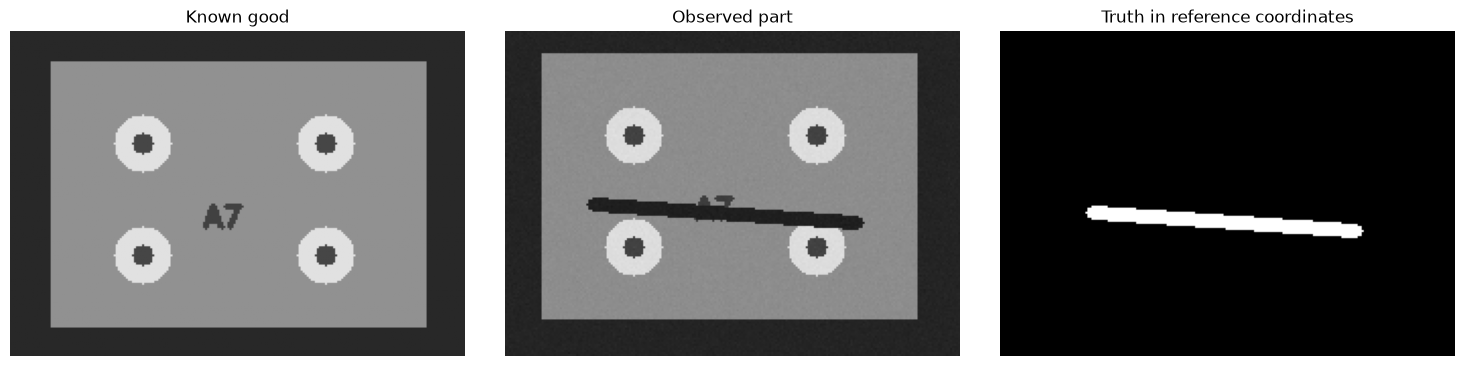

In [2]:
reference = np.full((160, 224), 40, np.uint8)
cv2.rectangle(reference, (20, 15), (204, 145), 145, -1)
for center in [(65, 55), (155, 55), (65, 110), (155, 110)]:
    cv2.circle(reference, center, 14, 225, -1)
    cv2.circle(reference, center, 5, 70, -1)
cv2.putText(reference, "A7", (95, 96), cv2.FONT_HERSHEY_SIMPLEX, .5, 65, 2)
roi_mask = np.zeros_like(reference)
roi_mask[23:138, 28:197] = 255

def make_inspection_sample(seed, defective):
    sample_rng = np.random.default_rng(seed)
    image = reference.copy()
    truth = np.zeros_like(reference)
    if defective:
        if seed % 3 == 0:
            cv2.circle(image, (155, 55), 14, 145, -1)  # missing pad
            cv2.circle(truth, (155, 55), 14, 255, -1)
        else:
            y = int(sample_rng.integers(70, 105))
            cv2.line(image, (45, y), (175, y + 9), 35, 5)
            cv2.line(truth, (45, y), (175, y + 9), 255, 5)
    shift = sample_rng.integers(-4, 5, size=2).astype(float)
    matrix = np.array([[1, 0, shift[0]], [0, 1, shift[1]]], np.float32)
    shifted = cv2.warpAffine(image, matrix, (224, 160), borderMode=cv2.BORDER_REPLICATE)
    noise = sample_rng.normal(0, 2, shifted.shape)
    brightness = sample_rng.uniform(-12, 12)
    shifted = np.clip(shifted.astype(np.float32) + noise + brightness, 0, 255).astype(np.uint8)
    return {"image": shifted, "truth": truth, "defective": bool(defective), "shift": shift, "seed": seed}

sample = make_inspection_sample(103, True)
show_images([reference, sample["image"], sample["truth"]], ["Known good", "Observed part", "Truth in reference coordinates"])


## Step 2 — Align before subtracting

Even a good part shifted three pixels produces differences around every edge.
`phaseCorrelate(reference, observed)` estimates translation `(dx, dy)` from the
Fourier transforms. To align the observation, apply the **negative** displacement.
The response is a diagnostic peak measure, not a calibrated probability.

We assume translation only. Rotation, scale, strong perspective changes, repeated
textures, or large defects can invalidate this estimate. A production system
needs an alignment-quality gate and labeled examples of those failures.


True shift: [-2. -4.] Estimated: [-1.35 -4.11] Response: 0.636


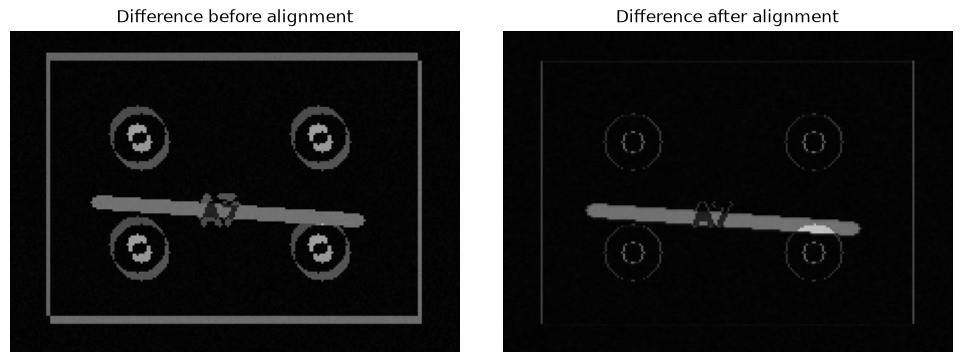

In [3]:
def align_part(observed):
    window = cv2.createHanningWindow((reference.shape[1], reference.shape[0]), cv2.CV_32F)
    shift, response = cv2.phaseCorrelate(reference.astype(np.float32), observed.astype(np.float32), window)
    matrix = np.array([[1, 0, -shift[0]], [0, 1, -shift[1]]], np.float32)
    aligned = cv2.warpAffine(observed, matrix, (reference.shape[1], reference.shape[0]), borderMode=cv2.BORDER_REPLICATE)
    return aligned, np.array(shift), float(response)

aligned, estimated_shift, response = align_part(sample["image"])
print("True shift:", sample["shift"], "Estimated:", estimated_shift.round(2), "Response:", round(response, 3))
assert np.linalg.norm(estimated_shift - sample["shift"]) < 1.5
show_images([cv2.absdiff(reference, sample["image"]), cv2.absdiff(reference, aligned)], ["Difference before alignment", "Difference after alignment"])


## Step 3 — Correct brightness and isolate changed regions

Compute the median intensity difference inside the region of interest (ROI).
If most ROI pixels are unchanged, this estimates a global brightness offset
robustly. Subtract it in floating point to avoid unsigned-integer wraparound.

Threshold the absolute difference, open with a 3×3 kernel to remove isolated noise,
then keep connected components above a minimum area. A thin real scratch can be
removed by this cleanup; minimum defect size is an explicit design choice.


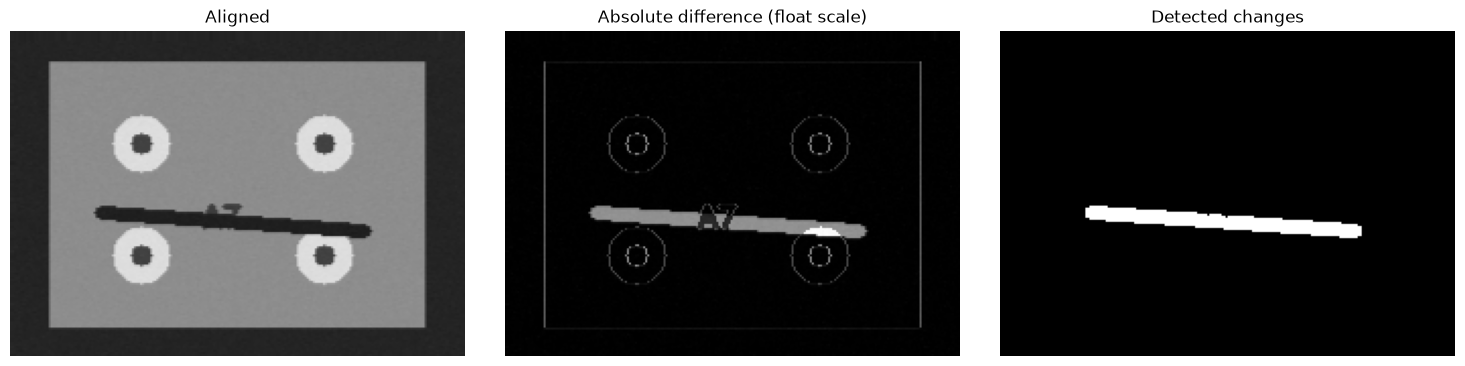

Regions: [{'box': [42, 86, 136, 16], 'area': 949}]


In [4]:
def inspect_part(observed, difference_threshold=25, min_area=30):
    aligned, shift, response = align_part(observed)
    offset = float(np.median((aligned.astype(np.float32) - reference)[roi_mask > 0]))
    corrected = np.clip(aligned.astype(np.float32) - offset, 0, 255)
    difference = np.abs(corrected - reference.astype(np.float32))
    binary = np.where((difference > difference_threshold) & (roi_mask > 0), 255, 0).astype(np.uint8)
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    count, labels, stats, centers = cv2.connectedComponentsWithStats(cleaned)
    prediction = np.zeros_like(cleaned)
    regions = []
    for label in range(1, count):  # zero is the background
        x, y, w, h, area = stats[label]
        if area >= min_area:
            prediction[labels == label] = 255
            regions.append({"box": [int(x), int(y), int(w), int(h)], "area": int(area)})
    return {"mask": prediction, "aligned": aligned, "difference": difference,
            "regions": regions, "defective": bool(regions), "shift": shift,
            "alignment_response": response, "brightness_offset": offset}

result = inspect_part(sample["image"])
show_images([result["aligned"], result["difference"], result["mask"]], ["Aligned", "Absolute difference (float scale)", "Detected changes"])
print("Regions:", result["regions"])


## Step 4 — Measure what matters

Image-level **precision** asks: of flagged parts, how many were defective?
**Recall** asks: of defective parts, how many were flagged? A false negative
ships a defect; a false positive causes unnecessary review. The acceptable
tradeoff depends on the application.

Pixel intersection-over-union (IoU) measures localization. For a defective image,
`IoU = intersection / union` of predicted and true masks. We report it on positive
samples separately so many perfect empty masks do not inflate the score.


In [5]:
def evaluate(samples, threshold, min_area=30):
    tp = fp = fn = tn = 0
    positive_ious = []
    for item in samples:
        output = inspect_part(item["image"], threshold, min_area)
        predicted, actual = output["defective"], item["defective"]
        tp += int(predicted and actual)
        fp += int(predicted and not actual)
        fn += int(not predicted and actual)
        tn += int(not predicted and not actual)
        if actual:
            p, t = output["mask"] > 0, item["truth"] > 0
            positive_ious.append(float(np.count_nonzero(p & t) / max(1, np.count_nonzero(p | t))))
    precision = tp / max(1, tp + fp)
    recall = tp / max(1, tp + fn)
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "precision": precision,
            "recall": recall, "F1": 2 * precision * recall / max(1e-12, precision + recall),
            "positive_mean_IoU": float(np.mean(positive_ious))}

validation = [make_inspection_sample(1000 + i, i % 2 == 1) for i in range(20)]
candidates = [(threshold, evaluate(validation, threshold)) for threshold in [15, 25, 35, 45]]
for threshold, metrics in candidates:
    print(f"Threshold {threshold}: {metrics}")
# Select on validation only. Localization breaks ties in image-level F1.
best_threshold, _ = max(candidates, key=lambda pair: (pair[1]["F1"], pair[1]["positive_mean_IoU"]))
print("Chosen threshold:", best_threshold)


Threshold 15: {'TP': 10, 'FP': 0, 'FN': 0, 'TN': 10, 'precision': 1.0, 'recall': 1.0, 'F1': 1.0, 'positive_mean_IoU': 0.9783530825980608}
Threshold 25: {'TP': 10, 'FP': 0, 'FN': 0, 'TN': 10, 'precision': 1.0, 'recall': 1.0, 'F1': 1.0, 'positive_mean_IoU': 0.9836692751759099}
Threshold 35: {'TP': 10, 'FP': 0, 'FN': 0, 'TN': 10, 'precision': 1.0, 'recall': 1.0, 'F1': 1.0, 'positive_mean_IoU': 0.9549793573745827}
Threshold 45: {'TP': 10, 'FP': 0, 'FN': 0, 'TN': 10, 'precision': 1.0, 'recall': 1.0, 'F1': 1.0, 'positive_mean_IoU': 0.955755854879999}
Chosen threshold: 25


The generated parts are deliberately easy to inspect. High validation scores
establish that the code handles these known conditions, not that it is ready
for a factory. Test data below use different seeds but the same generator;
they do not establish performance on new defect families or real cameras.

## Step 5 — Freeze settings, then evaluate held-out samples

Once you inspect the test results, resist changing settings to improve this same
test set. Further development needs a new final holdout. Here `min_area=30` was
fixed before validation; threshold is the only tuned parameter.


Held-out results: {'TP': 12, 'FP': 0, 'FN': 0, 'TN': 12, 'precision': 1.0, 'recall': 1.0, 'F1': 1.0, 'positive_mean_IoU': 0.9853153747152343}


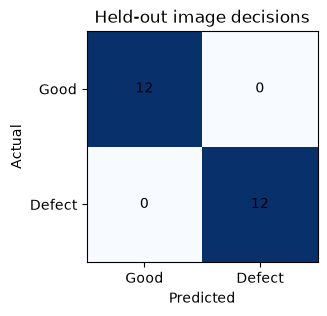

In [6]:
held_out = [make_inspection_sample(2000 + i, i % 2 == 1) for i in range(24)]
test_metrics = evaluate(held_out, best_threshold)
print("Held-out results:", test_metrics)
assert sum(test_metrics[key] for key in ["TP", "FP", "FN", "TN"]) == len(held_out)
assert 0 <= test_metrics["positive_mean_IoU"] <= 1

matrix = np.array([[test_metrics["TN"], test_metrics["FP"]], [test_metrics["FN"], test_metrics["TP"]]])
fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(matrix, cmap="Blues")
for (r, c), value in np.ndenumerate(matrix):
    ax.text(c, r, str(value), ha="center", va="center")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Good", "Defect"], yticklabels=["Good", "Defect"], xlabel="Predicted", ylabel="Actual", title="Held-out image decisions")
plt.show()
plt.close(fig)


## Step 6 — Review overlays and export evidence

An aggregate score can hide a systematic error. Inspect overlays on both good
and defective samples. Red rectangles show accepted components. Saving the
reference, settings, and metrics makes an experiment easier to reproduce.


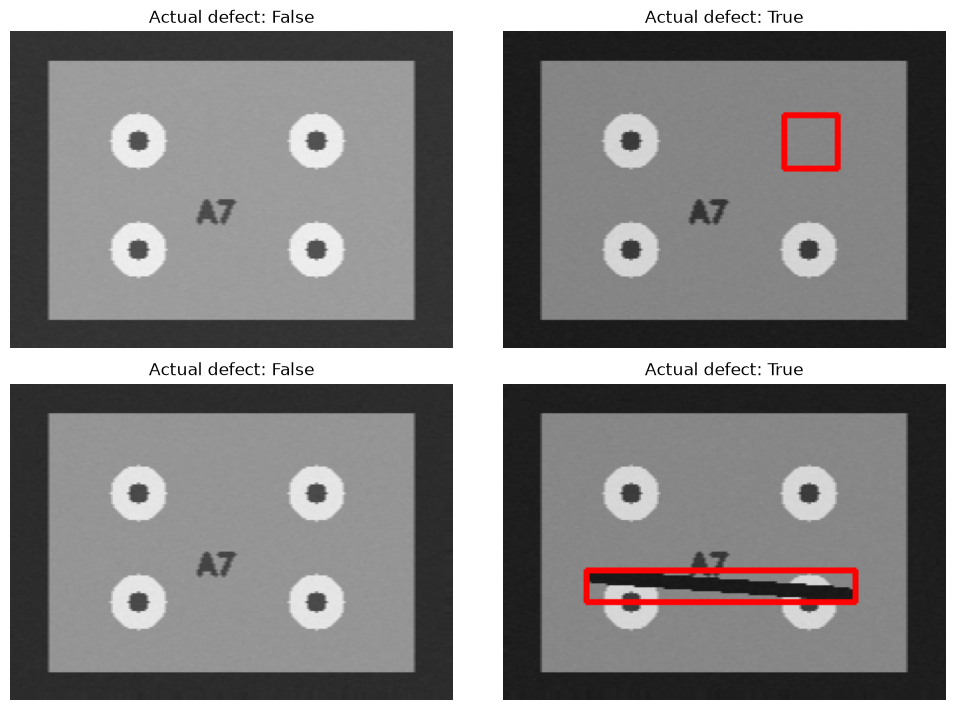

Saved report: C:\Users\Hareram ray\AI\OpencvPractical\outputs\19_inspection\report.json


In [7]:
import json

overlays = []
for item in held_out[:4]:
    output = inspect_part(item["image"], best_threshold)
    overlay = cv2.cvtColor(output["aligned"], cv2.COLOR_GRAY2BGR)
    for region in output["regions"]:
        x, y, w, h = region["box"]
        cv2.rectangle(overlay, (x, y), (x + w, y + h), (0, 0, 255), 2)
    overlays.append(overlay)
show_images(overlays, [f"Actual defect: {item['defective']}" for item in held_out[:4]], cols=2)
output_dir = ROOT / "outputs" / "19_inspection"
output_dir.mkdir(parents=True, exist_ok=True)
save_image(output_dir / "reference.png", reference)
save_image(output_dir / "example_overlay.png", overlays[1])
report = {"threshold": int(best_threshold), "min_area": 30, "test_metrics": test_metrics,
          "test_seeds": [item["seed"] for item in held_out], "opencv": cv2.__version__,
          "scope": "Generated translation/noise/global-brightness samples only"}
(output_dir / "report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
print("Saved report:", output_dir / "report.json")


## Stress test — Break an assumption

Add a local shadow to a **good** part. Global median compensation cannot remove a
local lighting change, so the inspector may call it a defect. A stronger system
might use controlled lighting, local normalization, a better image representation,
or learned segmentation. Each change still needs separate evaluation.


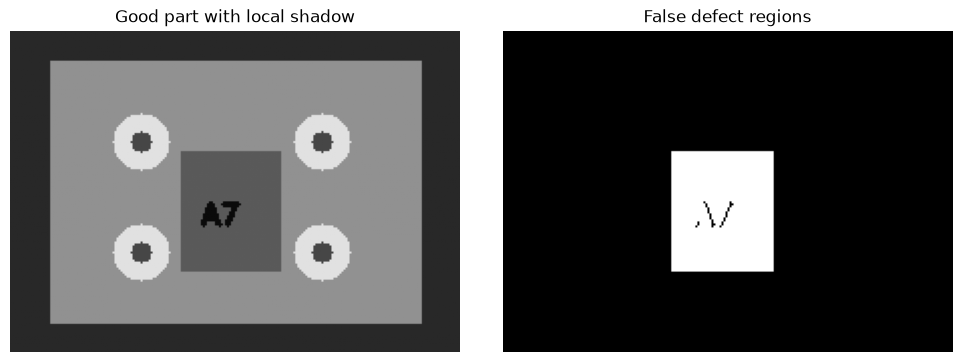

Flagged as defective: True


In [8]:
shadowed = reference.copy()
shadowed[60:120, 85:135] = np.clip(shadowed[60:120, 85:135].astype(np.int16) - 55, 0, 255).astype(np.uint8)
shadow_result = inspect_part(shadowed, best_threshold)
show_images([shadowed, shadow_result["mask"]], ["Good part with local shadow", "False defect regions"])
print("Flagged as defective:", shadow_result["defective"])


## Exercises — Try first

1. Measure validation performance for minimum areas 10, 30, and 100. Keep the test
   set closed while exploring. Which setting could miss small scratches?
2. Calculate the number of parts sent to review per 100 observations on the holdout.
3. Design a new data split that prevents near-duplicate photos of one physical part
   from appearing in both training and testing.
4. Add rotation or a tiny two-pixel scratch to the generator and evaluate as a new
   stress set, without silently adding it to the original accuracy claim.


In [9]:
# Your experiments and explanation go here.


## Worked solutions


In [10]:
for area in [10, 30, 100]:
    metrics = evaluate(validation, best_threshold, min_area=area)
    print(f"min_area={area}: F1={metrics['F1']:.3f}, positive IoU={metrics['positive_mean_IoU']:.3f}")
review_rate = 100 * (test_metrics["TP"] + test_metrics["FP"]) / len(held_out)
print(f"Holdout review rate: {review_rate:.1f} per 100 parts")


min_area=10: F1=1.000, positive IoU=0.984
min_area=30: F1=1.000, positive IoU=0.984
min_area=100: F1=1.000, positive IoU=0.984
Holdout review rate: 50.0 per 100 parts


For exercise 3, split by physical part and capture session, not by individual image.
Keep a separate camera/date if generalization across capture conditions matters.
For exercise 4, preserve the baseline generator and report stress-set performance
separately. If experiments guide design changes, reserve another final test set.

## Project extension and completion checklist

Photograph a small collection of household parts on a fixed background. Define
what counts as a defect before labeling. Record false positives and false negatives,
then investigate the failures with overlays. Do not use this exercise for safety-
critical quality decisions.

You should be able to explain the order of alignment/normalization/difference,
justify threshold and area settings, calculate precision/recall/IoU, and state at
least three conditions where the pipeline fails.

**References:** [Phase correlation](https://docs.opencv.org/4.x/d7/df3/group__imgproc__motion.html),
[shape analysis and connected components](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html).
Next: [20 — Performance and reproducible pipelines](20_performance_and_reproducible_pipelines.ipynb).
